In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
import seaborn as sns

In [ ]:
df=pd.read_csv("/content/student_exam_performance.csv")

# data has been downloaded from kaggle


In [ ]:
df.tail(4)

,student_id,age,gender,education_level,school_type,family_income,parent_education,urban_rural,previous_exam_score,previous_gpa,...,exam_difficulty,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score,performance_grade,pass_status,performance_level
99996,STU_099997,14,Female,High School,Public,Upper-Middle,Bachelor,Suburban,75.70,2.98,...,Easy,24,94,91,84.29,8.68,96.54,A,Pass,High
99997,STU_099998,16,Female,High School,Public,Upper-Middle,High School,Suburban,84.69,3.27,...,Medium,24,85,65,62.32,9.97,74.66,C,Pass,Medium
99998,STU_099999,15,Female,High School,Private,High,Master,Rural,74.70,3.06,...,Medium,28,93,81,100.00,10.00,85.85,A,Pass,High
99999,STU_100000,18,Female,Undergraduate,Charter,Lower-Middle,NaN,Urban,76.73,2.97,...,Medium,1,92,52,NaN,10.00,54.40,D,Pass,Low


In [ ]:
df.shape

(100000, 44)

In [ ]:
df.isnull().sum()

,0
student_id,0
age,0
gender,0
education_level,0
school_type,0
family_income,0
parent_education,6526
urban_rural,0
previous_exam_score,0
previous_gpa,7793


In [ ]:
df['pass_status'].value_counts()

,count
pass_status,
Pass,77389
Fail,22611


# creating contigency table to find probability

In [ ]:
table = pd.crosstab(df['gender'], df['pass_status'])

print(table)

pass_status   Fail   Pass
gender                   
Female       11048  37793
Male         11084  38046
Other          479   1550


P(A)= Number of passes/Total students

In [ ]:
P_of_A = (df['pass_status'] == 'Pass').mean()

print("P(A) =", P_of_A)

P(A) = 0.77389


# P(A∩B)=Female student who passed/Total students

In [ ]:
P_A_divide_B = (
    (df['pass_status'] == 'Pass') &
    (df['gender'] == 'Female')
).mean()

print("P(A ∩ B) =",P_A_divide_B)

P(A ∩ B) = 0.37793


P(A/B)= P(A ∩ B)/P(B)

In [ ]:
P_A_given_B = (
    ((df['pass_status'] == 'Pass') &
     (df['gender'] == 'Female')).sum()
    /
    (df['gender'] == 'Female').sum()
)

print("P(A | B) =", P_A_given_B)

P(A | B) = 0.7737966053111116


In [ ]:
df.describe()

,age,previous_exam_score,previous_gpa,attendance_percentage,assignment_completion_rate,study_hours_per_day,self_study_hours,private_tuition,online_learning_hours,practice_tests_completed,...,physical_activity_hours,stress_level,internet_access,online_course_hours,exam_preparation_days,questions_attempted,questions_correct,time_management_score,exam_anxiety_level,exam_score
count,100000.000000,100000.000000,92207.000000,90137.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,90387.000000,100000.000000,100000.000000
mean,17.005740,69.531033,2.780892,84.616882,69.724405,2.995725,2.094970,0.299800,2.004763,5.509170,...,2.487579,9.375640,0.918760,2.999453,15.501440,92.492150,57.298240,78.398551,8.927373,61.950072
std,1.999562,11.379108,0.478218,7.922485,12.127179,1.719466,1.266066,0.458173,2.005719,2.501131,...,2.413386,1.081613,0.273205,2.983732,8.644356,4.609376,15.028787,14.105155,1.354875,15.863644
min,14.000000,30.000000,1.000000,46.340000,20.000000,0.500000,0.250000,0.000000,0.000000,0.000000,...,0.000000,5.000000,0.000000,0.000000,1.000000,85.000000,0.000000,17.030000,1.000000,0.000000
25%,15.000000,61.820000,2.460000,79.210000,61.480000,1.720000,1.170000,0.000000,0.580000,4.000000,...,0.720000,9.000000,1.000000,0.860000,8.000000,88.000000,47.000000,68.790000,8.220000,51.240000
50%,17.000000,69.530000,2.780000,84.750000,69.570000,2.670000,1.840000,0.000000,1.380000,5.000000,...,1.730000,10.000000,1.000000,2.080000,16.000000,92.000000,57.000000,79.000000,9.490000,61.960000
75%,19.000000,77.232500,3.110000,90.170000,77.920000,3.910000,2.730000,1.000000,2.770000,7.000000,...,3.480000,10.000000,1.000000,4.150000,23.000000,96.000000,67.000000,89.210000,10.000000,72.730000
max,20.000000,100.000000,4.000000,100.000000,100.000000,12.000000,10.000000,1.000000,15.000000,20.000000,...,12.000000,10.000000,1.000000,20.000000,30.000000,100.000000,100.000000,100.000000,10.000000,100.000000


# let's take exam score for the normal distrbution

In [ ]:
mean= df['exam_score'].mean()
std=df['exam_score'].std()

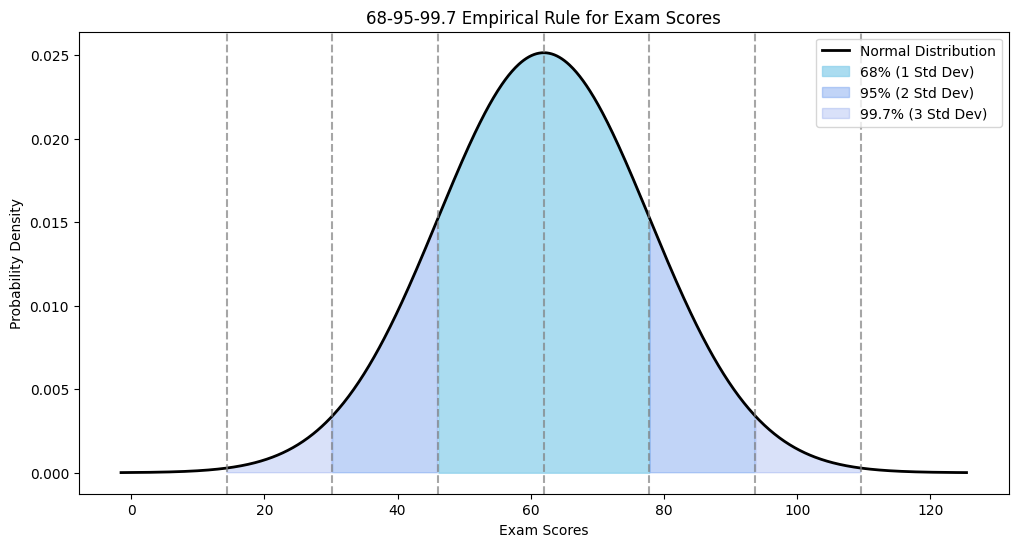

In [ ]:
x = np.linspace(mean - 4*std, mean + 4*std, 1000)
y = norm.pdf(x, mean, std)

plt.figure(figsize=(12, 6))

plt.plot(x, y, label='Normal Distribution', color='black', linewidth=2)

# Shade regions
plt.fill_between(x, y, where=(x >= mean-std) & (x <= mean+std),
                 alpha=0.7, label='68% (1 Std Dev)', color='skyblue')

plt.fill_between(x, y, where=((x >= mean-2*std) & (x <= mean-std)) | ((x >= mean+std) & (x <= mean+2*std)),
                 alpha=0.4, label='95% (2 Std Dev)', color='cornflowerblue')

plt.fill_between(x, y, where=((x >= mean-3*std) & (x <= mean-2*std)) | ((x >= mean+2*std) & (x <= mean+3*std)),
                 alpha=0.2, label='99.7% (3 Std Dev)', color='royalblue')

# Standard deviation lines
for i in range(-3, 4):
    plt.axvline(mean + i*std, linestyle='--', color='gray', alpha=0.7)

plt.title('68-95-99.7 Empirical Rule for Exam Scores')
plt.xlabel('Exam Scores')
plt.ylabel('Probability Density')
plt.legend()
plt.show()

# simulating binomial distrbution

In [ ]:
import numpy as np
n = 10
p = 0.7
size = 500

data = np.random.binomial(n, p, size)

print(data)

[ 8  9  8  7  8  6  7  3  7 10  8  7  8  8  9  7  9  6  8  5  7  6  8  7
  7  8  6  8  7  9  8  6  5  8  6 10  6  9  6  7  9  6  6  8  7  9  8  7
  8  5  7  7  4  5  6  7  6  7  9  9  6  9  6  9  8  6  8  6  6  8 10  7
  7  5  7  6 10  8 10  8  8  8  7  6  5  7  8  6  6  8  9  7  7  6  6  6
  6  6  9  9  8  6  8  8  5  8  7  7  3  8  6  7  4  8  6  8  7  6  5  7
  6  9  7  8  5  9  9  6  8  8  7  7  4  4  7  8  8  8  6  6  6  5  8  8
  4  8  7  8  7  7  7  7  8  4  7  8  7  6  8  5  6  7  5  7  7  9  5  5
  5  7  9  7  8  7  7  6  7  5  8  7  8  9 10  7  7  9  6  7  7  8  5  7
  8  9  8  8  7  6  7  8  5  7  7  3  7  5  8  8  5  5  7  7  7  7  9  9
  8  7  9  8  7  6  9  7  7  8  6  4  5  4  7  7  7  4  9  4  7  6  6  6
  6  7  6  7  7  8  6  6  7  5  6  6  5  8  5  7  7  9  6  4  3  4  8  5
  3  8  3  9  7 10  6  8  5  8  7  7  9  4  8  6  6  6  8  5 10  8  7  9
  6  7  5  8  5  6  7  7  7  6  7  7  7  6  8  7  5  7  8  7  7  7 10  8
  6  8 10  8  5  8  6  8  8  5  9  7  7  6  6  8  8

Shapiro‑Wilk p‑value (≈ normal if >0.05): 7.964444425606958e-15


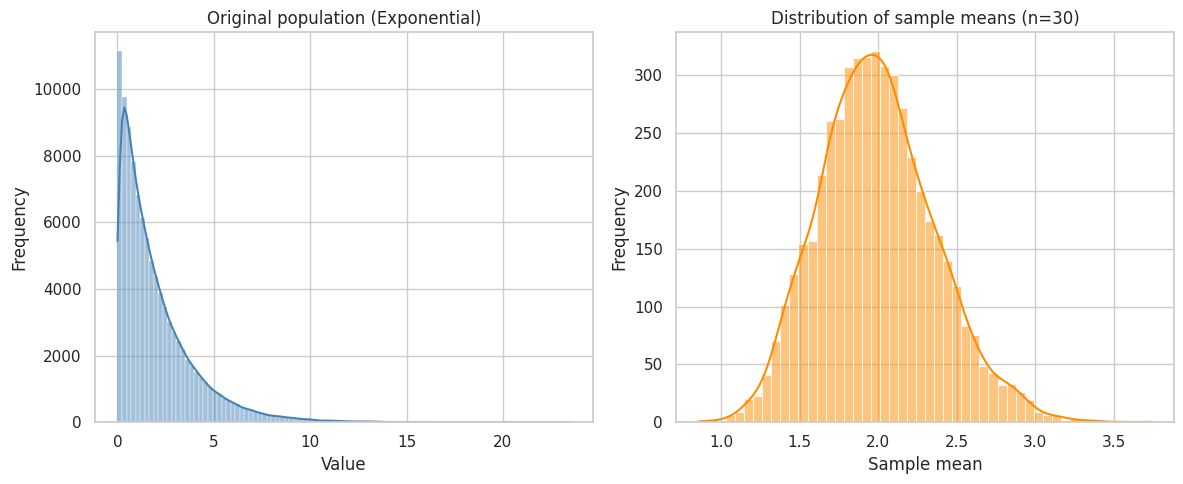

In [5]:
# central limit theorem
sns.set(style="whitegrid")

np.random.seed(42)
pop_size = 100_000
population = np.random.exponential(scale=2.0, size=pop_size)

sample_size = 30
n_samples   = 5_000

means = np.empty(n_samples)
for i in range(n_samples):
    sample = np.random.choice(population, size=sample_size, replace=False)
    means[i] = sample.mean()

fig, ax = plt.subplots(1, 2, figsize=(12,5))

#   a) Original population
sns.histplot(population, bins=100, kde=True, color='steelblue', ax=ax[0])
ax[0].set_title('Original population (Exponential)')
ax[0].set_xlabel('Value')
ax[0].set_ylabel('Frequency')

#   b) Distribution of sample means
sns.histplot(means, bins=50, kde=True, color='darkorange', ax=ax[1])
ax[1].set_title(f'Distribution of sample means (n={sample_size})')
ax[1].set_xlabel('Sample mean')
ax[1].set_ylabel('Frequency')


from scipy import stats
z = (means - means.mean())/means.std()
print('Shapiro‑Wilk p‑value (≈ normal if >0.05):',
      stats.shapiro(z[:5000])[1])

plt.tight_layout()
plt.show()